# Домашнее задание 7

**Тема 7.** Визуализация данных в Python: matplotlib, seaborn, plotly
**Данные:** `web_clients_correct.csv`, первые 15 строк
**Структура:** подготовка → функции → задание 1 → задание 2 → выводы → самопроверка

Строю диаграмму рассеяния «возраст — расходы» в Seaborn и Plotly, затем добавляю
линию регрессии через `regplot`.

Код разбит на функции: загрузка, проверка типов, построение графиков. Глобальных
переменных нет, каждая функция решает одну задачу.


## Подготовка

Импортирую библиотеки и включаю встроенный вывод графиков. Файл `web_clients_correct.csv`
лежит в этой же папке.


In [1]:
%matplotlib inline

from pathlib import Path

import pandas as pd
import plotly.express as px
import seaborn as sns
from IPython.display import Image, display

sns.set_theme(style="whitegrid", palette="deep")


## Функции

* `load_clients` — читает первые 15 строк;
* `check_columns` — проверяет типы и пропуски в столбцах для графика;
* `scatter_seaborn`, `scatter_plotly` — одна и та же диаграмма двумя библиотеками;
* `regression_seaborn` — диаграмма с линией регрессии;
* `correlation` — коэффициент корреляции и детерминация;
* `save_plotly_png` — статичная копия графика Plotly для GitHub.


In [2]:
def load_clients(file_path, rows=15):
    """Загружаю первые rows строк из CSV."""
    if not Path(file_path).exists():
        raise FileNotFoundError(f"Нет файла {file_path}: положите его рядом с ноутбуком.")
    return pd.read_csv(file_path, nrows=rows, encoding="utf-8")


def check_columns(clients, columns=("age", "bill")):
    """Проверяю типы и пропуски в столбцах, которые идут на график."""
    data = clients[list(columns)]
    return pd.DataFrame({
        "тип": data.dtypes.astype(str),
        "пропуски": data.isna().sum(),
        "минимум": data.min(),
        "максимум": data.max(),
    })


def scatter_seaborn(clients):
    """Диаграмма рассеяния возраста и расходов средствами Seaborn."""
    axes = sns.scatterplot(data=clients, x="age", y="bill", s=60)
    axes.set_title("Зависимость расходов от возраста (Seaborn)")
    axes.set_xlabel("age — возраст, лет")
    axes.set_ylabel("bill — расходы, руб.")
    return axes


def scatter_plotly(clients):
    """Та же диаграмма средствами Plotly: интерактивная версия."""
    figure = px.scatter(
        clients,
        x="age",
        y="bill",
        hover_data=["sex", "device_type"],
        labels={"age": "age — возраст, лет", "bill": "bill — расходы, руб."},
        title="Зависимость расходов от возраста (Plotly)",
    )
    figure.update_traces(marker=dict(size=9, opacity=0.85))
    return figure


def regression_seaborn(clients):
    """Диаграмма рассеяния с линией регрессии и доверительным интервалом."""
    axes = sns.regplot(
        data=clients,
        x="age",
        y="bill",
        ci=95,
        scatter_kws={"s": 60, "alpha": 0.8},
        line_kws={"color": "crimson", "linewidth": 2},
    )
    axes.set_title("Линия регрессии: расходы от возраста (Seaborn regplot)")
    axes.set_xlabel("age — возраст, лет")
    axes.set_ylabel("bill — расходы, руб.")
    return axes


def correlation(clients):
    """Коэффициент корреляции Пирсона и детерминация для пары age-bill."""
    coefficient = clients["age"].corr(clients["bill"])
    return coefficient, coefficient ** 2


def save_plotly_png(figure, file_name, width=900, height=480):
    """Сохраняю статичный PNG графика Plotly и показываю его в ноутбуке."""
    figure.write_image(file_name, width=width, height=height, scale=2)
    display(Image(file_name))
    return file_name


## Задание 1. Диаграмма рассеяния (Seaborn и Plotly)

Сначала проверяю данные, затем строю обе диаграммы по одним и тем же столбцам:
`age` по оси X, `bill` по оси Y.


Строк в выборке: 15

        тип  пропуски  минимум  максимум
age   int64         0       24        80
bill  int64         0      100      1126

--- Seaborn ---

--- Plotly: интерактивная версия ---



--- Plotly: статичная копия для GitHub ---


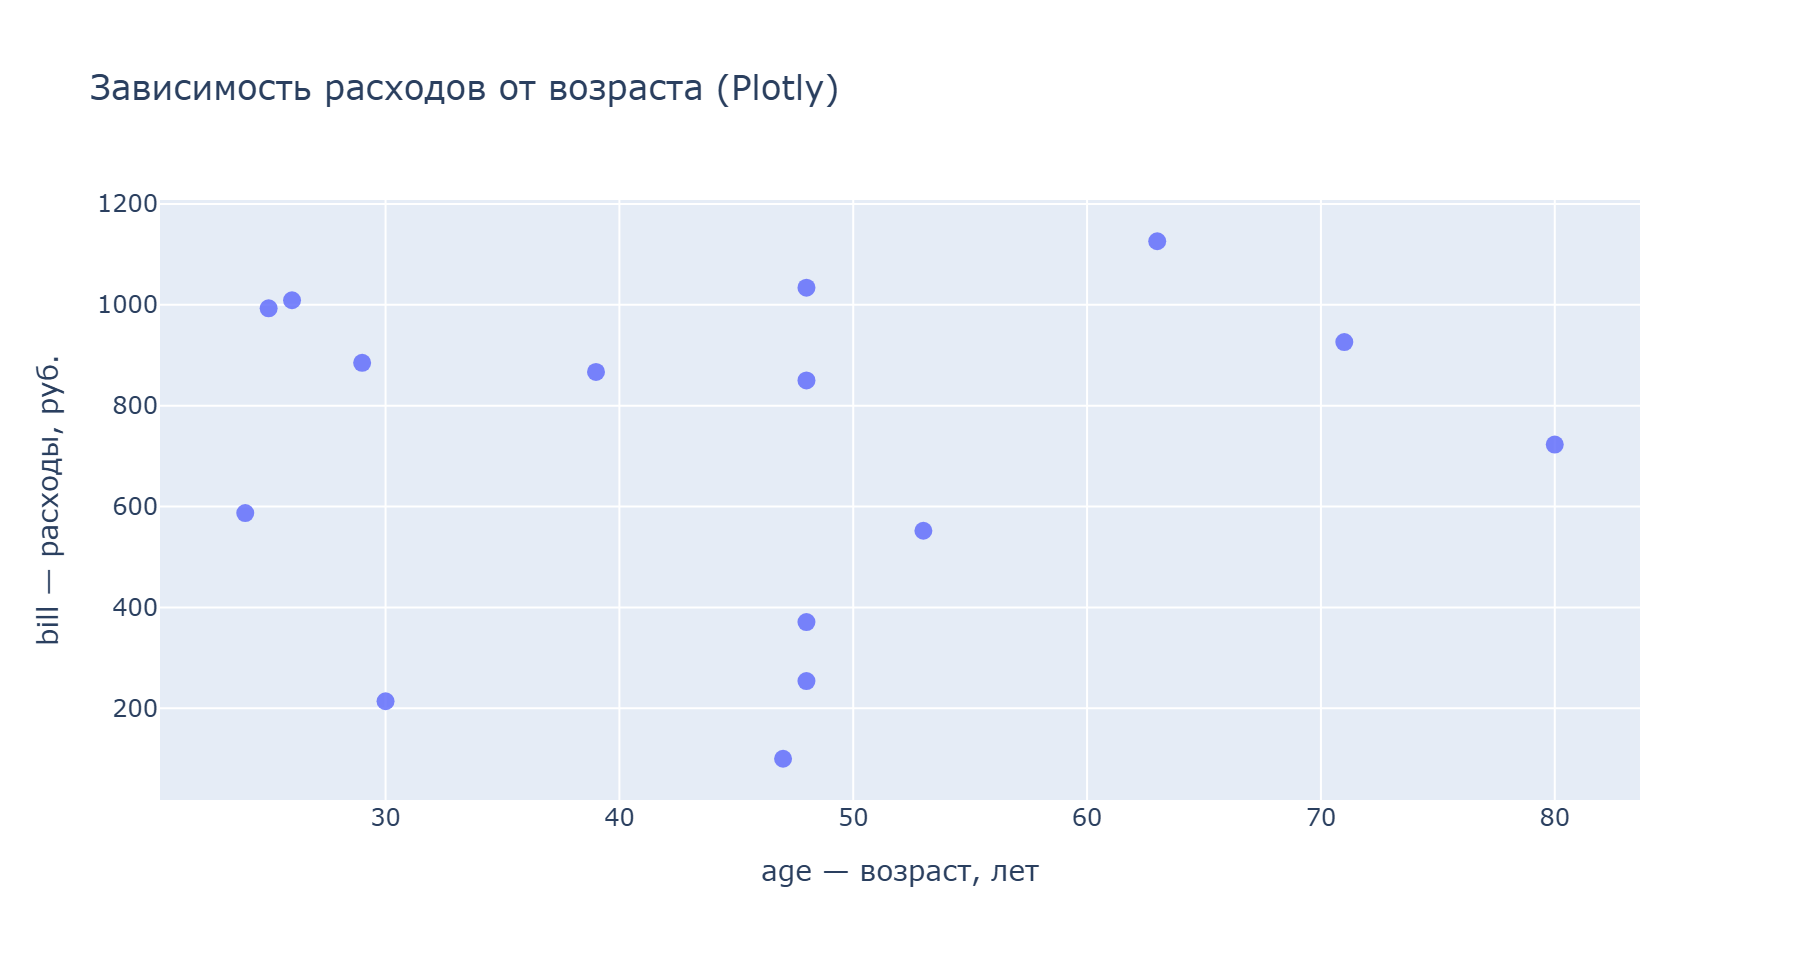

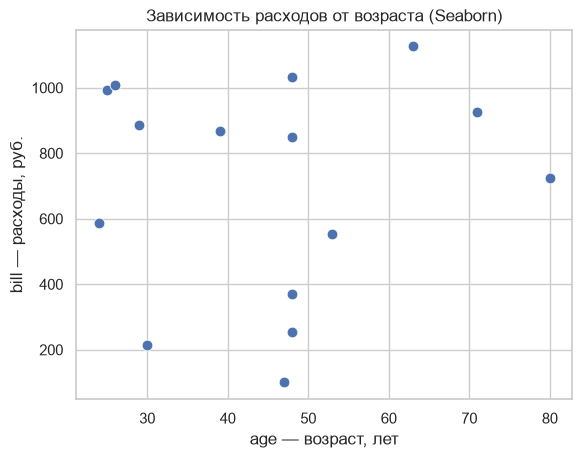

In [3]:
def task_1(file_path):
    clients = load_clients(file_path)
    print("Строк в выборке:", len(clients))
    print()
    print(check_columns(clients))

    print("\n--- Seaborn ---")
    scatter_seaborn(clients)

    print("\n--- Plotly: интерактивная версия ---")
    figure = scatter_plotly(clients)
    figure.show()

    print("\n--- Plotly: статичная копия для GitHub ---")
    save_plotly_png(figure, "task_1_plotly.png")


task_1("web_clients_correct.csv")


**Что видно на диаграмме.** Точки распределены по всему полю: рядом с 48 годами встречаются
и 100, и 850, и 1034 рубля. Самый крупный чек — 1126 рублей у клиентки 63 лет, самый
маленький — 100 рублей у клиента 47 лет. Крайние значения с возрастом не связаны.

Разброс по `bill` большой (100–1126), по `age` — от 24 до 80 лет. Поэтому диаграмма
рассеяния здесь уместнее линейного графика: она показывает каждое наблюдение отдельно.


## Задание 2. Линия регрессии (`regplot`)

Добавляю к диаграмме рассеяния линию линейной регрессии. Дополнительно считаю коэффициент
корреляции Пирсона: он показывает, насколько линия вообще описывает данные.


Коэффициент корреляции Пирсона r = 0.0640
Коэффициент детерминации R^2 = 0.0041


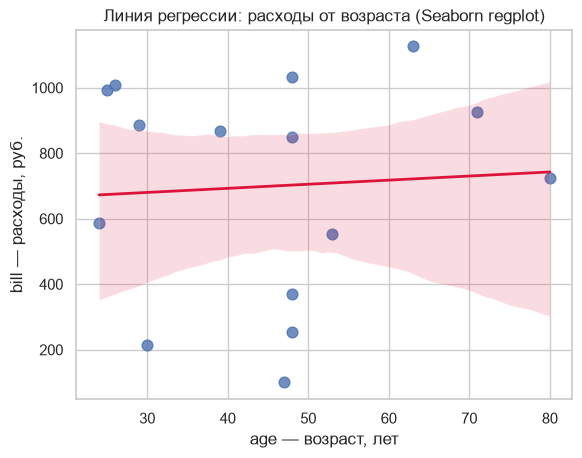

In [4]:
def task_2(file_path):
    clients = load_clients(file_path)
    regression_seaborn(clients)

    coefficient, determination = correlation(clients)
    print(f"Коэффициент корреляции Пирсона r = {coefficient:.4f}")
    print(f"Коэффициент детерминации R^2 = {determination:.4f}")


task_2("web_clients_correct.csv")


## Выводы

1. Диаграмма рассеяния построена двумя библиотеками: Seaborn даёт статичный график,
   Plotly — интерактивный, при наведении видны пол, тип устройства и браузер клиента.
2. Линия регрессии почти горизонтальная: `r ≈ 0,06`, `R² ≈ 0,004`. Возрастом объясняется
   меньше половины процента разброса расходов.
3. Связи между возрастом клиента и суммой расходов в этой выборке нет. Наиболее вероятная
   причина — объём: 15 строк слишком мало, чтобы увидеть закономерность, даже если
   она есть в генеральной совокупности.
4. Доверительный интервал вокруг линии широкий и расширяется к краям выборки — ещё одно
   следствие маленькой выборки.


## Самопроверка

* Seaborn: диаграмма рассеяния `age` × `bill`, подписи осей по заданию — да.
* Plotly: та же диаграмма, интерактивная, с подсказками при наведении — да.
* Seaborn: линия регрессии через `regplot`, доверительный интервал 95 % — да.
* Данные не изменялись: функции работают с DataFrame только на чтение.
* Глобальных переменных нет, каждая функция отвечает за одну задачу — да.
